# 1차 실험: 모델 계열 비교 (입력 1,042컬럼 고정)

| 항목 | 내용 |
|---|---|
| 목적 | Day1에서 확정한 1,042컬럼을 그대로 두고, 여러 계열의 모델을 같은 조건으로 비교해 2·3차에서 집중할 모델을 고른다 |
| 입력 | 이 폴더의 `preprocess.py` + `feature_columns.json` (Day1 버전 그대로) → 8,000행 × 1,042컬럼 |
| 분할 | `../common/splits.csv` 고정 분할 — 테스트 20%(1,600행)는 사용하지 않음, 개발 80%(6,400행)로 parent 그룹 5-fold × 2회 = 10 fold |
| 주 지표 | F1 (임계값 0.5) · 보조: AUC, Precision, Recall, 학습 시간 |
| 하이퍼파라미터 | 모델별 무난한 기본값으로 고정 (튜닝은 3차) |

실행 방법
- 위에서부터 순서대로 실행하면 된다. 처음 실행하면 10 fold × 9개 모델을 학습한다(약 8~10분, CPU 2코어 기준).
- 결과는 `results/`에 저장되며, `RUN_CV = False`로 바꾸면 저장된 결과를 불러와 그래프만 다시 그린다.
- 테스트 세트는 최종 모델이 정해진 뒤 마지막 차수에서 한 번만 평가한다. 여기서 테스트 점수를 보고 모델을 고르면 테스트가 검증 세트가 되어 점수가 낙관적으로 나오기 때문이다.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, f1_score, confusion_matrix

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "common"))
from preprocess import preprocess_train, load_feature_columns   # 이 폴더의 preprocess.py
from evaluate import load_splits, run_cv, summarize, corrected_paired_ttest, metrics
from models import build_models

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False
RES = HERE / "results"; RES.mkdir(exist_ok=True)
RUN_CV = True        # False: results/의 저장된 결과를 불러옴

## 1. 데이터 로드와 분할 확인

In [2]:
df, X, y, groups = preprocess_train(HERE.parent.parent / "train.csv")
cols = load_feature_columns()
df = load_splits(df)

dev = (df["set"] == "dev").values
Xd = X[dev].reset_index(drop=True).astype("float32")
yd = y[dev]
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)
df_dev = df[dev].reset_index(drop=True)

print("전체:", X.shape, "| 개발:", Xd.shape, "| 테스트:", int((~dev).sum()), "행 (이번 차수에서는 사용 안 함)")
print("parent 겹침(개발∩테스트):", len(set(df[dev].parent) & set(df[~dev].parent)))
summary = pd.DataFrame({
    "행 수": df.groupby("set").size(),
    "label=1 비율": df.groupby("set")["label"].mean().round(3),
})
display(summary)
display(pd.crosstab(folds["fold_r0"], yd, normalize="index").round(3).rename(columns={0: "label 0", 1: "label 1"}).T)

전체: (8000, 1042) | 개발: (6400, 1042) | 테스트: 1600 행 (이번 차수에서는 사용 안 함)
parent 겹침(개발∩테스트): 0


,행 수,label=1 비율
set,,
dev,6400,0.542
test,1600,0.542


fold_r0,0,1,2,3,4
col_0,,,,,
label 0,0.458,0.458,0.458,0.458,0.457
label 1,0.542,0.542,0.542,0.542,0.543


In [3]:
fp_cols = [c for c in cols if c.startswith(("ecfp_", "fcfp_"))]
cont_cols = [c for c in cols if c not in fp_cols and c not in ("is_salt", "has_stereo_tag")]
print("Fingerprint 비트:", len(fp_cols), "| 연속·개수형:", len(cont_cols), "| 0/1 플래그: 2  → 합계", len(cols))

Fingerprint 비트: 1027 | 연속·개수형: 13 | 0/1 플래그: 2  → 합계 1042


## 2. 비교할 모델

| 계열 | 모델 | 설정 | 넣은 이유 |
|---|---|---|---|
| 선형 | LogReg | C=0.05, 연속형 표준화 | 기준선, Day1과 같은 설정 |
| 커널 | SVM_RBF | C=1, gamma=scale, 연속형 표준화 | 고차원 이진 특성에서 강한 경우가 많음 |
| 거리 기반 | KNN_Jaccard | k=15, 거리 가중, Fingerprint 비트만 | 구조 유사도(Tanimoto = 1 − Jaccard 거리)로 이웃의 라벨을 따름. EDA에서 최근접 이웃 라벨 일치율 0.757 |
| 배깅 트리 | RandomForest, ExtraTrees | 트리 500개, max_features=sqrt | 튜닝 없이도 안정적 |
| 부스팅 트리 | LightGBM, XGBoost, CatBoost | 400~500회, 학습률 0.05, 컬럼 샘플링 0.3 | Day1에서 가장 높았던 계열, 구현별 차이 확인 |
| 신경망 | MLP | 은닉층 128, early stopping, 연속형 표준화 | Day1 2위 계열 |

- 표준화는 파이프라인 안에 있어 fold의 학습 부분으로만 fit된다(검증 정보 누수 없음).
- SVM은 확률을 직접 내지 않으므로 decision function을 시그모이드로 0~1로 바꿨다. 0.5가 결정경계와 같아 F1은 정확하지만, 확률로 해석하면 안 된다.

## 3. 10-fold 교차검증 실행

In [4]:
models = build_models(cont_cols, fp_cols)
if RUN_CV:
    all_scores, all_oof = [], {}
    for name, mk in models.items():
        t0 = time.time()
        s, o = run_cv(mk, Xd, yd, folds, name)
        all_scores.append(s)
        for r in o.columns:
            all_oof[f"{name}|{r}"] = o[r].values
        print(f"{name:13s} F1 {s.f1.mean():.4f} ± {s.f1.std(ddof=0):.4f} | AUC {s.auc.mean():.4f} | {time.time()-t0:5.0f}s", flush=True)
    scores = pd.concat(all_scores, ignore_index=True)
    oof = pd.DataFrame(all_oof)
    oof.insert(0, "SMILES", df_dev["SMILES"]); oof.insert(1, "label", yd)
    scores.to_csv(RES / "cv_scores.csv", index=False)
    oof.to_csv(RES / "oof_predictions.csv", index=False)
else:
    scores = pd.read_csv(RES / "cv_scores.csv")
    oof = pd.read_csv(RES / "oof_predictions.csv")

LogReg        F1 0.7798 ± 0.0044 | AUC 0.8315 |     9s


SVM_RBF       F1 0.8040 ± 0.0048 | AUC 0.8631 |    85s


KNN_Jaccard   F1 0.7652 ± 0.0094 | AUC 0.8240 |    72s


RandomForest  F1 0.8177 ± 0.0063 | AUC 0.8737 |    41s


ExtraTrees    F1 0.8086 ± 0.0064 | AUC 0.8614 |    59s


LightGBM      F1 0.8150 ± 0.0062 | AUC 0.8757 |    22s


XGBoost       F1 0.8131 ± 0.0100 | AUC 0.8729 |    25s


CatBoost      F1 0.8097 ± 0.0067 | AUC 0.8683 |   128s


MLP           F1 0.7962 ± 0.0075 | AUC 0.8530 |    17s


## 4. 결과 요약

In [5]:
tbl = summarize(scores)
tbl.to_csv(RES / "summary.csv")
best = tbl.index[0]
print("기준점: 모두 1로 예측할 때 F1 =", round(f1_score(yd, np.ones_like(yd)), 3))
display(tbl.round(4).style.background_gradient(subset=["F1", "AUC"], cmap="Blues").format(precision=4))

기준점: 모두 1로 예측할 때 F1 = 0.703


,F1,F1_std,AUC,AUC_std,Precision,Recall,fit_sec(1fold)
model,,,,,,,
RandomForest,0.8177,0.0063,0.8737,0.0069,0.7937,0.8434,3.8811
LightGBM,0.8150,0.0062,0.8757,0.0058,0.8017,0.8290,2.1794
XGBoost,0.8131,0.0100,0.8729,0.0070,0.7974,0.8299,2.4824
CatBoost,0.8097,0.0067,0.8683,0.0078,0.7914,0.8292,12.7985
ExtraTrees,0.8086,0.0064,0.8614,0.0074,0.7932,0.8251,5.6534
SVM_RBF,0.8040,0.0048,0.8631,0.0064,0.7829,0.8266,6.3559
MLP,0.7962,0.0075,0.8530,0.0060,0.7782,0.8168,1.6440
LogReg,0.7798,0.0044,0.8315,0.0032,0.7644,0.7962,0.8126
KNN_Jaccard,0.7652,0.0094,0.8240,0.0092,0.7655,0.7651,0.0374


### 4-1. 1위 모델과 차이가 의미 있는가 (보정 짝지은 t-검정)
- 같은 fold에서 나온 두 모델의 F1 차이 10개를 비교한다. Day1의 "평균 − 표준편차" 규칙보다 정확한 방법이다.
- CV fold들은 학습 데이터가 겹쳐 독립이 아니므로 Nadeau & Bengio(2003)의 보정을 적용했다.
- `wins`는 10개 fold 중 그 모델이 1위 모델보다 높았던 횟수, `p_value` < 0.05면 1위와 차이가 있다고 본다.

In [6]:
tt = corrected_paired_ttest(scores, best)
tt["1위와 구분 가능(p<0.05)"] = np.where(tt.p_value < 0.05, "예", "아니오")
tt.to_csv(RES / "paired_ttest_vs_best.csv")
print("1위:", best)
display(tt.round(4))

1위: RandomForest


,diff_vs_best,t,p_value,wins,folds,1위와 구분 가능(p<0.05)
model,,,,,,
LightGBM,-0.0027,-0.8111,0.4382,4,10,아니오
XGBoost,-0.0046,-0.8666,0.4087,4,10,아니오
CatBoost,-0.0080,-2.2874,0.0480,0,10,예
ExtraTrees,-0.0090,-2.5764,0.0299,1,10,예
SVM_RBF,-0.0136,-4.0963,0.0027,0,10,예
MLP,-0.0214,-4.0922,0.0027,0,10,예
LogReg,-0.0378,-6.9029,0.0001,0,10,예
KNN_Jaccard,-0.0525,-12.2172,0.0000,0,10,예


## 5. 시각화

### 5-1. 모델별 F1 분포 (10 fold)

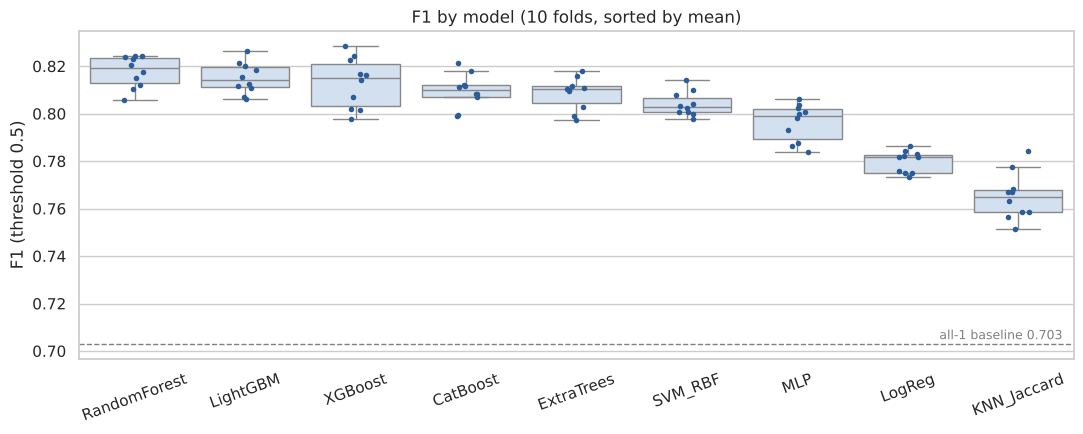

In [7]:
order = tbl.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=scores, x="model", y="f1", order=order, color="#cfe0f3", ax=ax, showfliers=False)
sns.stripplot(data=scores, x="model", y="f1", order=order, color="#2b5d9a", size=4, ax=ax)
ax.axhline(0.703, ls="--", c="gray", lw=1); ax.text(len(order) - 0.6, 0.705, "all-1 baseline 0.703", ha="right", fontsize=9, color="gray")
ax.set_xlabel(""); ax.set_ylabel("F1 (threshold 0.5)"); ax.set_title("F1 by model (10 folds, sorted by mean)")
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(RES / "fig_f1_box.png", dpi=130); plt.show()

### 5-2. 성능과 학습 시간

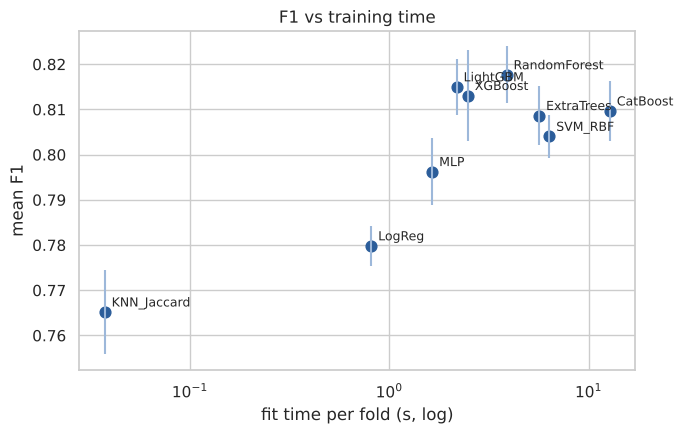

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(tbl["fit_sec(1fold)"], tbl["F1"], s=60, color="#2b5d9a")
ax.errorbar(tbl["fit_sec(1fold)"], tbl["F1"], yerr=tbl["F1_std"], fmt="none", ecolor="#9db8da")
for m, r in tbl.iterrows():
    ax.annotate(m, (r["fit_sec(1fold)"], r["F1"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("fit time per fold (s, log)"); ax.set_ylabel("mean F1")
ax.set_title("F1 vs training time"); plt.tight_layout(); plt.savefig(RES / "fig_f1_time.png", dpi=130); plt.show()

### 5-3. ROC 곡선과 Precision·Recall

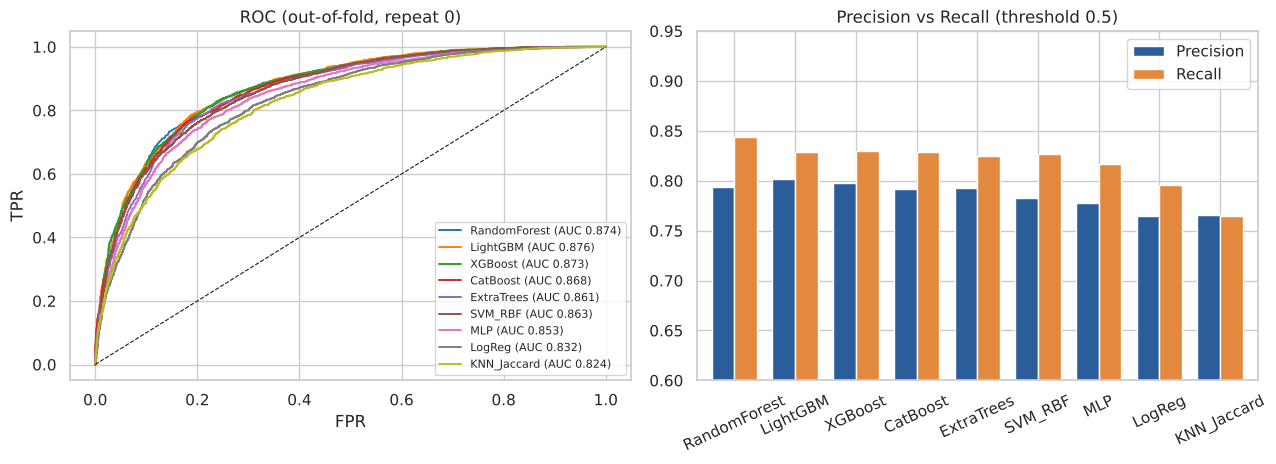

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
pal = sns.color_palette("tab10", len(order))
for i, m in enumerate(order):
    fpr, tpr, _ = roc_curve(yd, oof[f"{m}|r0"])
    ax[0].plot(fpr, tpr, lw=1.4, color=pal[i], label=f"{m} (AUC {tbl.loc[m,'AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[0].set_title("ROC (out-of-fold, repeat 0)"); ax[0].legend(fontsize=8, loc="lower right")

pr = tbl[["Precision", "Recall"]]
pr.plot.bar(ax=ax[1], color=["#2b5d9a", "#e3893f"], width=0.75)
ax[1].set_ylim(0.6, 0.95); ax[1].set_title("Precision vs Recall (threshold 0.5)"); ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(RES / "fig_roc_pr.png", dpi=130); plt.show()

### 5-4. 임계값에 따른 F1 (4차 임계값 조정의 가능성)
- 지금은 모두 0.5로 자른다. F1은 임계값에 따라 달라지므로 0.5가 최적이 아닐 수 있다.
- 아래 최적 임계값은 OOF 전체에서 고른 값이라 낙관적이다. 실제 조정은 4차에서 fold 안에서 고르고 바깥 fold로 확인한다.

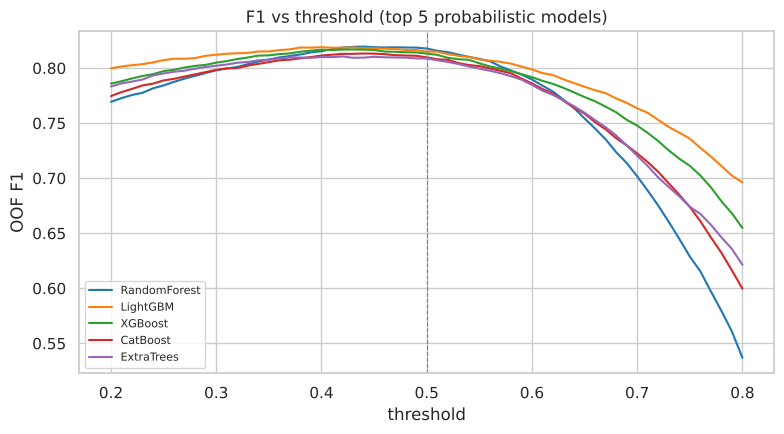

,F1@0.5,best_thr,F1@best,gain
model,,,,
RandomForest,0.8177,0.44,0.8195,0.0018
LightGBM,0.8150,0.40,0.8190,0.0040
XGBoost,0.8131,0.43,0.8168,0.0037
CatBoost,0.8097,0.44,0.8132,0.0035
ExtraTrees,0.8087,0.42,0.8105,0.0018
MLP,0.7964,0.38,0.8007,0.0044
LogReg,0.7798,0.43,0.7906,0.0108
KNN_Jaccard,0.7652,0.40,0.7811,0.0159


In [10]:
ths = np.linspace(0.2, 0.8, 61)
prob_models = [m for m in order if m != "SVM_RBF"]          # SVM 점수는 확률이 아님
rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, m in enumerate(prob_models[:5]):
    f1s = [np.mean([f1_score(yd, oof[f"{m}|r{r}"] >= t) for r in (0, 1)]) for t in ths]
    ax.plot(ths, f1s, label=m, color=pal[order.index(m)])
for m in prob_models:
    f1s = [np.mean([f1_score(yd, oof[f"{m}|r{r}"] >= t) for r in (0, 1)]) for t in ths]
    k = int(np.argmax(f1s)); rows.append((m, f1s[30], ths[k], f1s[k], f1s[k] - f1s[30]))
ax.axvline(0.5, c="gray", ls="--", lw=0.8); ax.set_xlabel("threshold"); ax.set_ylabel("OOF F1")
ax.set_title("F1 vs threshold (top 5 probabilistic models)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RES / "fig_threshold.png", dpi=130); plt.show()
thr_tbl = pd.DataFrame(rows, columns=["model", "F1@0.5", "best_thr", "F1@best", "gain"]).set_index("model")
display(thr_tbl.round(4))

### 5-5. 모델끼리 예측이 얼마나 다른가 (4차 앙상블의 가능성)
- 앙상블은 서로 다른 실수를 하는 모델을 섞어야 효과가 있다. 예측 확률의 순위 상관이 낮을수록 서로 다르다.
- 아래 단순 평균 앙상블은 미리보기다. 확률을 내는 상위 모델들의 OOF 확률을 평균해 0.5로 잘랐다.

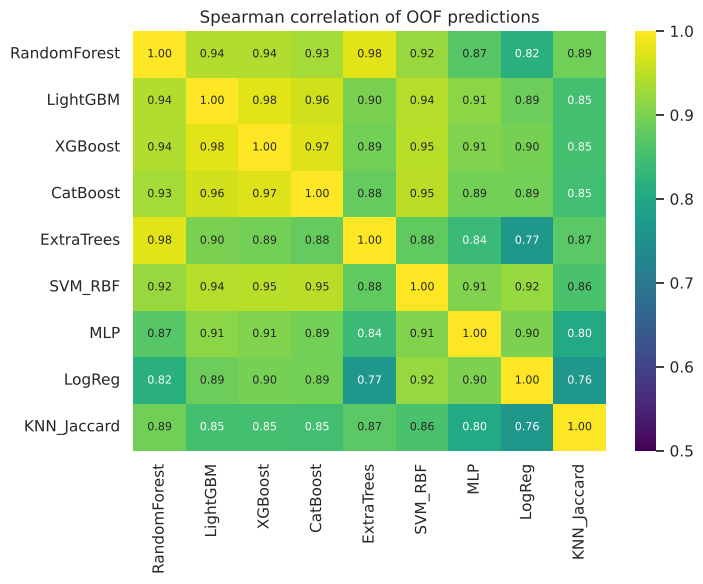

,구성,OOF F1 (2회 평균)
0,1위 단독: RandomForest,0.8177
1,"상위 2개 평균: RandomForest, LightGBM",0.8192
2,"상위 3개 평균: RandomForest, LightGBM, XGBoost",0.8191
3,"상위 4개 평균: RandomForest, LightGBM, XGBoost, Cat...",0.8174
4,"상위 5개 평균: RandomForest, LightGBM, XGBoost, Cat...",0.8186
5,"계열 섞기: RandomForest, MLP, LogReg",0.8083


In [11]:
P = pd.DataFrame({m: oof[f"{m}|r0"] for m in order})
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(P.corr(method="spearman"), annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Spearman correlation of OOF predictions"); plt.tight_layout(); plt.savefig(RES / "fig_pred_corr.png", dpi=130); plt.show()

def ens_f1(ms):
    return np.mean([f1_score(yd, np.mean([oof[f"{m}|r{r}"] for m in ms], axis=0) >= 0.5) for r in (0, 1)])
single = {m: np.mean([f1_score(yd, oof[f"{m}|r{r}"] >= 0.5) for r in (0, 1)]) for m in prob_models}
ens_rows = [("1위 단독: " + prob_models[0], single[prob_models[0]])]
for k in (2, 3, 4, 5):
    ens_rows.append((f"상위 {k}개 평균: " + ", ".join(prob_models[:k]), ens_f1(prob_models[:k])))
div = [prob_models[0]] + [m for m in ["MLP", "LogReg", "KNN_Jaccard"] if m in prob_models and m != prob_models[0]][:2]
ens_rows.append(("계열 섞기: " + ", ".join(div), ens_f1(div)))
display(pd.DataFrame(ens_rows, columns=["구성", "OOF F1 (2회 평균)"]).round(4))

## 6. 오류 분석: 어디서 틀리는가
### 6-1. 학습 데이터와 얼마나 닮은 화합물에서 틀리는가
- 검증 화합물마다, 그 fold의 학습 화합물 중 가장 비슷한 화합물과의 Tanimoto 유사도(ECFP 1,024비트 전체)를 계산했다.
- 유사도 구간별로 1위 모델의 정답률과 F1을 본다. 학습 때 본 적 없는 구조에서 얼마나 떨어지는지가 2차 실험의 방향을 정한다.

,화합물 수,label=1 비율,RandomForest 정답률,RandomForest F1,LogReg 정답률
bin,,,,,
<0.4,457.0,0.663,0.742,0.821,0.696
0.4-0.5,223.0,0.619,0.726,0.783,0.695
0.5-0.6,404.0,0.557,0.755,0.791,0.735
0.6-0.7,862.0,0.530,0.777,0.794,0.730
0.7-0.8,2062.0,0.504,0.779,0.786,0.742
≥0.8,2392.0,0.547,0.839,0.857,0.795


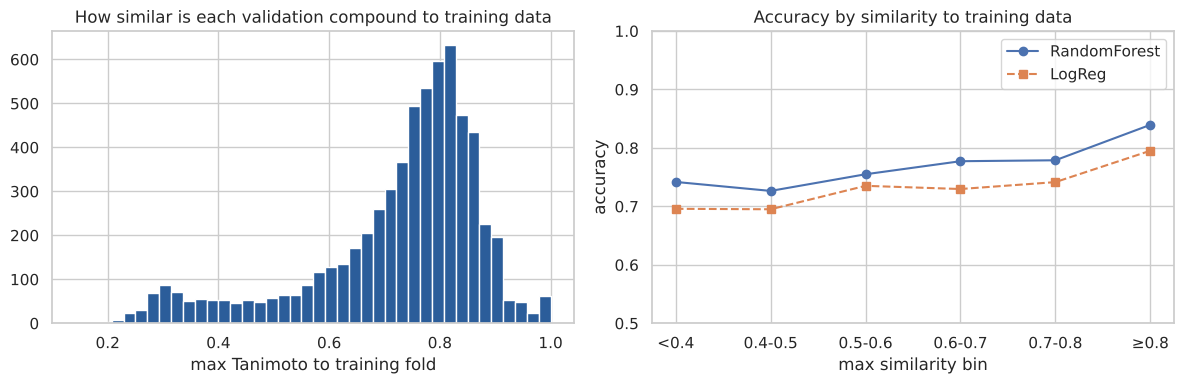

In [12]:
ecfp_all = [f"ecfp_{i}" for i in range(1024)]
E = df_dev[ecfp_all].values.astype(np.float32)
cnt = E.sum(1)
max_sim = np.zeros(len(E))
f0 = folds["fold_r0"].values
for k in range(5):
    va, tr = f0 == k, f0 != k
    inter = E[va] @ E[tr].T
    sim = inter / (cnt[va][:, None] + cnt[tr][None, :] - inter + 1e-9)
    max_sim[va] = sim.max(1)

bins = [0, 0.4, 0.5, 0.6, 0.7, 0.8, 1.01]
lab = ["<0.4", "0.4-0.5", "0.5-0.6", "0.6-0.7", "0.7-0.8", "≥0.8"]
b = pd.cut(max_sim, bins, labels=lab, right=False)
ana = pd.DataFrame({"bin": b, "y": yd, "best": (oof[f"{best}|r0"] >= 0.5).astype(int),
                    "logreg": (oof["LogReg|r0"] >= 0.5).astype(int)})
sim_tbl = ana.groupby("bin", observed=True).apply(lambda g: pd.Series({
    "화합물 수": len(g), "label=1 비율": g.y.mean(),
    f"{best} 정답률": (g.best == g.y).mean(), f"{best} F1": f1_score(g.y, g.best),
    "LogReg 정답률": (g.logreg == g.y).mean()}))
display(sim_tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(max_sim, bins=40, color="#2b5d9a"); ax[0].set_xlabel("max Tanimoto to training fold"); ax[0].set_title("How similar is each validation compound to training data")
ax[1].plot(lab, sim_tbl[f"{best} 정답률"], "o-", label=best); ax[1].plot(lab, sim_tbl["LogReg 정답률"], "s--", label="LogReg")
ax[1].set_ylim(0.5, 1); ax[1].set_xlabel("max similarity bin"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].set_title("Accuracy by similarity to training data")
plt.tight_layout(); plt.savefig(RES / "fig_similarity_error.png", dpi=130); plt.show()

### 6-2. 1위 모델의 혼동행렬
- label 1 = 독성 없음(Positive). 오른쪽 위(실제 0 → 예측 1)는 독성 물질을 안전하다고 판단한 경우다.

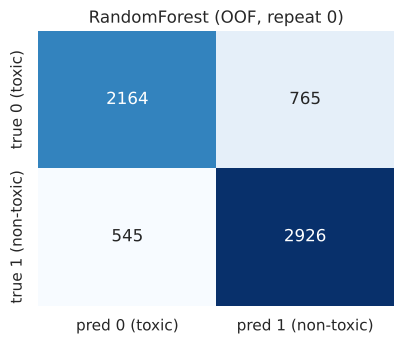

In [13]:
cm = confusion_matrix(yd, (oof[f"{best}|r0"] >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["pred 0 (toxic)", "pred 1 (non-toxic)"], yticklabels=["true 0 (toxic)", "true 1 (non-toxic)"])
ax.set_title(f"{best} (OOF, repeat 0)"); plt.tight_layout(); plt.savefig(RES / "fig_confusion.png", dpi=130); plt.show()

### 6-3. 트리 모델은 어떤 특성 그룹을 쓰는가
- 개발 세트 전체로 LightGBM을 한 번 학습해, 분할 이득(gain)을 특성 그룹별로 합쳤다.
- 그룹별 컬럼 수와 비교하면 컬럼 하나당 기여가 큰 그룹이 보인다. 해석용이며 변수 선택에는 쓰지 않는다.

,컬럼 수,gain 비중,컬럼당 비중(배)
ECFP,644,0.425,0.688
FCFP,383,0.325,0.885
Descriptor,3,0.131,45.387
RDKit,12,0.119,10.347


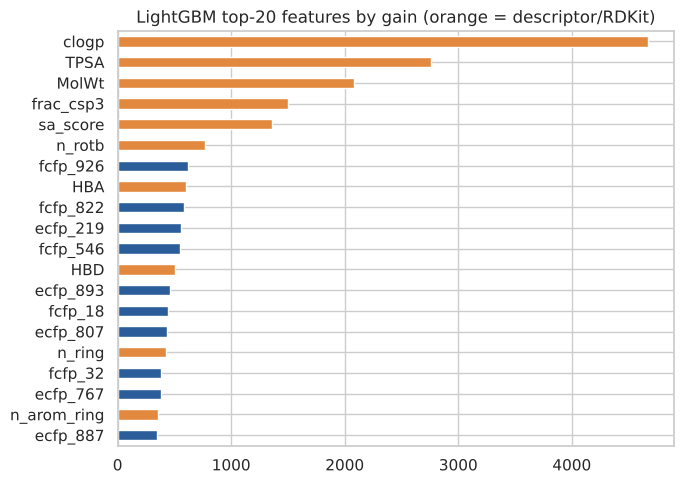

In [14]:
lgbm = models["LightGBM"](); lgbm.fit(Xd, yd)
imp = pd.Series(lgbm.booster_.feature_importance("gain"), index=cols)
grp = pd.Series(np.select([imp.index.str.startswith("ecfp_"), imp.index.str.startswith("fcfp_"),
                           imp.index.isin(["MolWt", "clogp", "sa_score"])], ["ECFP", "FCFP", "Descriptor"], "RDKit"), index=cols)
gtab = pd.DataFrame({"컬럼 수": grp.value_counts(), "gain 비중": imp.groupby(grp).sum() / imp.sum()})
gtab["컬럼당 비중(배)"] = gtab["gain 비중"] / (gtab["컬럼 수"] / len(cols))
display(gtab.sort_values("gain 비중", ascending=False).round(3))
top = imp.sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 5))
top[::-1].plot.barh(ax=ax, color=["#e3893f" if not c.startswith(("ecfp", "fcfp")) else "#2b5d9a" for c in top.index[::-1]])
ax.set_title("LightGBM top-20 features by gain (orange = descriptor/RDKit)"); plt.tight_layout(); plt.savefig(RES / "fig_importance.png", dpi=130); plt.show()

## 7. 결론과 2차 실험 제안

결과 표는 4절, 그래프는 5·6절 참고.

### 판단
1. 상위 그룹은 RandomForest · LightGBM · XGBoost다. 1위 RandomForest와 LightGBM·XGBoost의 차이는 통계적으로 구분되지 않는다(p = 0.44, 0.41). 반대로 CatBoost 이하 6개는 1위보다 유의하게 낮다.
2. 트리 계열이 1~5위를 모두 차지했다. 비트 1,027개와 연속형 15개가 섞인 입력에서, 스케일링 없이 변수 간 상호작용을 학습하는 트리가 유리했다.
3. 거리 기반 KNN이 가장 낮았다. Fingerprint 유사도만으로는 부족하고 물리·화학 특성이 함께 필요하다는 뜻이다.
4. KNN을 뺀 8개 모델에서 Recall이 Precision보다 높다(KNN은 둘이 같음). 비독성(1)으로 예측하는 경향이 있어서, 독성 물질을 안전하다고 판단하는 오류가 더 많다.

### 인사이트 (2차 이후 방향의 근거)
| 관찰 | 수치 | 의미 |
|---|---|---|
| 연속형 특성의 기여가 크다 | LightGBM gain에서 Descriptor 3개가 13.1%(컬럼당 평균의 45배), RDKit 12개가 11.9%(10배). 상위 6개 특성이 모두 연속형(clogp, TPSA, MolWt, frac_csp3, sa_score, n_rotb) | 물리·화학 특성을 늘리면 성능이 오를 여지가 크다. RDKit 전체 descriptor(217개)나 Mordred(약 1,600개)를 시도할 근거 |
| (주의) gain의 한계 | 연속형 변수는 나눌 수 있는 지점이 많아 0/1 비트보다 gain이 크게 잡히는 경향이 있다 | 정확한 기여는 2차에서 descriptor를 실제로 늘려 F1로 확인한다 |
| 라벨 상관이 약했던 변수도 트리에서는 중요 | MolWt(라벨 상관 0.01 미만)가 gain 3위, frac_csp3가 4위 | 단독 상관으로 변수를 빼지 않은 Day1 판단이 맞았다. 다른 변수와의 상호작용으로 쓰인다 |
| 처음 보는 구조에서 정답률이 떨어진다 | 학습 데이터와 최대 유사도 0.8 이상: 정답률 0.839 / 0.4 미만: 0.742 / 0.4~0.5: 0.726 | 구조가 낯선 화합물을 보완할 특성(물리·화학 descriptor, 다른 종류의 Fingerprint)이 필요하다 |
| 임계값 조정 효과는 작다 | 최적 임계값 0.40~0.44, F1 상승 +0.002~+0.004 (트리 모델, OOF 기준이라 낙관적) | 4차에서 할 일이지만 큰 개선은 기대하기 어렵다 |
| 상위 트리 모델끼리 예측이 거의 같다 | 예측 순위 상관 0.94~0.98. RandomForest + LightGBM 평균 앙상블 0.8192(+0.0015) | 같은 입력의 트리끼리 섞는 앙상블은 효과가 작다. 다른 입력 표현으로 학습한 모델을 섞어야 한다 |

### 2차 실험 제안 (우선순위 순)
모델은 상위 3개(RandomForest, LightGBM, XGBoost)로 좁히고, 비교용으로 SVM_RBF를 함께 둔다.

| 우선순위 | 시도 | 근거 | 방법 |
|---|---|---|---|
| 1 | 물리·화학 descriptor 확장 | 연속형 특성의 컬럼당 기여가 Fingerprint의 10~45배 | RDKit 전체 217개 → 상수·중복(상관 0.95 이상) 제거. 이후 Mordred(약 1,600개)도 같은 방식으로 비교 |
| 2 | Fingerprint 표현 바꾸기 | 처음 보는 구조에서 정답률 0.74 | 입체 정보 반영(useChirality), 비트 대신 개수(count) Fingerprint, radius 3, 2,048비트. MACCS(166), Atom-pair, Topological torsion 추가 |
| 3 | PTFP 다시 추가 | Day1에서는 고정 하이퍼파라미터로 차이가 없었음 | 트리 모델에서만 재확인 |
| 4 | 차원 축소 · 특성 선택 | 컬럼이 수천 개로 늘어날 때 필요 | Fingerprint에 TruncatedSVD(100~300차원), fold 안에서 중요도 상위 k개 선택. 트리보다 SVM·MLP·LogReg에서 효과를 기대 |

- 1·2번을 하면 `preprocess.py`가 바뀌므로, 2차 폴더에 새 `preprocess.py`를 둔다. 분할은 `common/splits.csv`를 그대로 써서 1차와 같은 fold로 비교한다.
- 변수 선택이나 차원 축소는 반드시 fold 안에서 fit한다. 개발 세트 전체로 고르면 검증 점수가 부풀려진다.

### 3차 이후 (예정)
- 3차: 상위 모델 하이퍼파라미터 튜닝 (Optuna, fold 안에서). RandomForest는 `max_features`·`min_samples_leaf`, 부스팅은 `num_leaves`·학습률·트리 수·정규화
- 4차: 임계값 최적화(fold 안에서 선택) + 서로 다른 입력으로 학습한 모델의 앙상블·스태킹
- 5차: 테스트 세트 1회 평가 → 8,000행 전체로 재학습 → `predict_input.csv` 927행 예측 → `predict_output_작성자.csv` 생성